# Superposition (H) — CUDA-Q Implementation

**Primitive:** Superposition via Hadamard gate

**SETUP (must match the Qiskit notebook exactly for results to line up)**
- N QUBITS: 2
- GATES APPLIED: Hadamard (H) on every qubit -> equal superposition of all basis states
- QUBIT ORDERING (contract): qubit 0 = rightmost bit in printed bitstring
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive

**Theory recap:** identical to the Qiskit version -- H|0> = (|0>+|1>)/sqrt(2). Applying H to
every qubit of a register starting in |00...0> produces the uniform superposition where every
basis state has probability 1/2^n. For n=2, all four states |00>, |01>, |10>, |11> each get
probability 0.25.

**Important ordering warning:** CUDA-Q's native state-vector indexing treats qubit 0 as the
**most-significant** bit (opposite of Qiskit's rightmost/least-significant convention). This
notebook explicitly reverses bit order after extracting the state so the final printed
dictionary matches the SETUP convention and is directly diffable against `QISKIT_RESULT`.
(For this specific primitive the reversal has no visible effect, since a uniform superposition
is symmetric under any bit permutation -- but the same reindexing code is used here as in every
other primitive so the pipeline stays identical and auditable.)

**IMPORTANT: Run every cell in order, top to bottom** (Kernel -> Restart & Run All).

In [18]:
# Run this cell first if you get ModuleNotFoundError.
# Correct package name is "cudaq" (NOT "cuda-quantum" -- that name has no prebuilt wheel and breaks pip).
# Requires pip >= 24.0, and Linux (x86_64/aarch64) or macOS (arm64/Apple Silicon). Windows needs WSL.
!pip install --upgrade pip -q
!pip install -q cudaq
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.


In [19]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import cudaq

N_QUBITS = 2
SHOTS = 10000
SEED = 42

cudaq.set_random_seed(SEED)

## 1. Build the kernel explicitly, gate by gate

In [ ]:
@cudaq.kernel
def superposition_kernel():
    q = cudaq.qvector(2)
    # Superposition operation: Hadamard on each qubit -> (|0>+|1>)/sqrt(2) per qubit,
    # giving a uniform superposition over all 2^n basis states.
    h(q[0])
    h(q[1])

**Note:** the kernel above is hardcoded for `N_QUBITS = 2` with an `h(...)` call per qubit,
mirroring exactly the gates the Qiskit circuit applies. If you change `N_QUBITS` in the setup
cell, add/remove the matching `h(q[...])` lines here -- CUDA-Q kernel bodies are compiled
ahead-of-time, so they can't take a runtime-length Python loop over qubit count the way the
Qiskit circuit builder does.

## 2. Draw/visualize the circuit

In [ ]:
# Native CUDA-Q text drawing
print(cudaq.draw(superposition_kernel))

     ╭───╮
q0 : ┤ h ├
     ├───┤
q1 : ┤ h ├
     ╰───╯



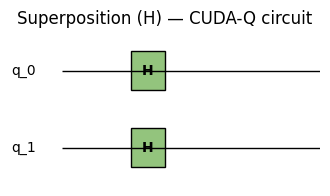

In [ ]:
# Matplotlib circuit diagram, styled to resemble the Qiskit mpl output
fig, ax = plt.subplots(figsize=(4, 2))

wire_labels = [f"q_{i}" for i in range(N_QUBITS)]
for i, label in enumerate(wire_labels):
    y = N_QUBITS - 1 - i
    ax.hlines(y, 0, 3, color="black", linewidth=1)
    ax.text(-0.3, y, label, va="center", ha="right", fontsize=10)

for q in range(N_QUBITS):
    y = N_QUBITS - 1 - q
    ax.add_patch(plt.Rectangle((0.8, y - 0.25), 0.4, 0.5, facecolor="#93c47d", edgecolor="black"))
    ax.text(1.0, y, "H", va="center", ha="center", fontsize=10, fontweight="bold")

ax.set_xlim(-0.6, 3)
ax.set_ylim(-0.5, N_QUBITS - 0.5)
ax.axis("off")
ax.set_title("Superposition (H) — CUDA-Q circuit")

fig.savefig("superposition_cudaq_circuit.png", bbox_inches="tight")
fig

## 3. Explicit matrix representation of the key operator (Hadamard)

In [ ]:
H_matrix = (1 / np.sqrt(2)) * np.array([[1, 1],
                                          [1, -1]], dtype=complex)
print("Single-qubit Hadamard gate matrix:")
print(np.round(H_matrix, 4))

Single-qubit Hadamard gate matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]


In [ ]:
# Full 4x4 operator H(x)H, constructed manually from gate definitions
# (same tensor-product convention as Qiskit: qubit 0 rightmost in basis ordering
# {|00>, |01>, |10>, |11>}).
full_op = np.kron(H_matrix, H_matrix)

print(f"Full {2**N_QUBITS}x{2**N_QUBITS} operator H(x)H (basis {{|00>, |01>, |10>, |11>}}):")
print(np.round(full_op.real, 4))

Full 4x4 operator H(x)H (basis {|00>, |01>, |10>, |11>}):
[[ 0.5  0.5  0.5  0.5]
 [ 0.5 -0.5  0.5 -0.5]
 [ 0.5  0.5 -0.5 -0.5]
 [ 0.5 -0.5 -0.5  0.5]]


## 4. Exact statevector, reordered + global-phase normalized

In [ ]:
state = cudaq.get_state(superposition_kernel)
raw_amps = np.array(state)

print("Raw CUDA-Q amplitudes (native ordering, qubit0 = MSB):")
print(np.round(raw_amps, 4))

Raw CUDA-Q amplitudes (native ordering, qubit0 = MSB):
[0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]


In [ ]:
# --- Explicit reindexing: CUDA-Q native (qubit0=MSB) -> SETUP convention (qubit0=rightmost/LSB) ---
def reorder_cudaq_to_qiskit_convention(amps, n_qubits):
    dim = 2 ** n_qubits
    reordered = np.zeros(dim, dtype=complex)
    for cudaq_index in range(dim):
        cudaq_bits = format(cudaq_index, f"0{n_qubits}b")   # qubit0 = MSB (CUDA-Q native)
        target_bits = cudaq_bits[::-1]                        # qubit0 = rightmost (SETUP)
        target_index = int(target_bits, 2)
        reordered[target_index] = amps[cudaq_index]
    return reordered

amps_reordered = reorder_cudaq_to_qiskit_convention(raw_amps, N_QUBITS)
print("Reordered amplitudes (qubit0 = rightmost, matches SETUP convention):")
print(np.round(amps_reordered, 4))

Reordered amplitudes (qubit0 = rightmost, matches SETUP convention):
[0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]


In [ ]:
# Global phase normalization -- identical method to the Qiskit notebook.
def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_norm, bitstrings = normalize_global_phase(amps_reordered, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector amplitudes (phase-normalized):")
print(np.round(amps_norm, 4))
print()
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector amplitudes (phase-normalized):
[0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]

Exact statevector probabilities (qubit0 = rightmost):
{'00': np.float64(0.25), '01': np.float64(0.25), '10': np.float64(0.25), '11': np.float64(0.25)}


## 5. Measurement: sample, plot histogram

In [ ]:
result = cudaq.sample(superposition_kernel, shots_count=SHOTS)
raw_counts = {bs: result.count(bs) for bs in result}
print("Raw CUDA-Q counts (native bitstring ordering, qubit0 = MSB):")
print(raw_counts)

Raw CUDA-Q counts (native bitstring ordering, qubit0 = MSB):
{'11': 2473, '10': 2497, '01': 2580, '00': 2450}


In [ ]:
# Reverse each sampled bitstring the same way as the statevector, to match SETUP convention
sampled_probs = {}
for bs, c in raw_counts.items():
    reordered_bs = bs[::-1]
    sampled_probs[reordered_bs] = sampled_probs.get(reordered_bs, 0) + c

sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in sampled_probs.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}), qubit0 = rightmost:")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42), qubit0 = rightmost:
{'00': 0.245, '01': 0.2497, '10': 0.258, '11': 0.2473}


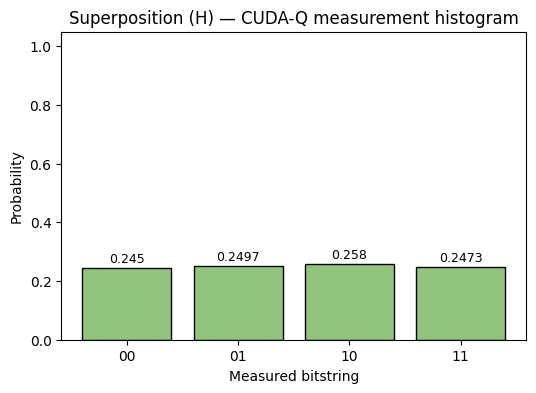

In [ ]:
# Matplotlib bar chart styled like Qiskit's plot_histogram()
fig2, ax2 = plt.subplots(figsize=(6, 4))
labels = list(sampled_probs.keys())
values = list(sampled_probs.values())

ax2.bar(labels, values, color="#93c47d", edgecolor="black")
ax2.set_xlabel("Measured bitstring")
ax2.set_ylabel("Probability")
ax2.set_title("Superposition (H) — CUDA-Q measurement histogram")
ax2.set_ylim(0, 1.05)
for i, v in enumerate(values):
    ax2.text(i, v + 0.02, str(v), ha="center", fontsize=9)

fig2.savefig("superposition_cudaq_histogram.png", bbox_inches="tight")
fig2

## 6. Gate / operation count

In [ ]:
gate_count = N_QUBITS  # one H gate per qubit
print(f"Gate/operation count: {gate_count}")

Gate/operation count: 2


## 7. Convention notes

In [ ]:
print("Qubit ordering: CUDA-Q's cudaq.get_state() and cudaq.sample() natively index/report")
print("bitstrings with qubit 0 as the MOST-significant (leftmost) bit -- the opposite of Qiskit's")
print("convention. This notebook explicitly reversed every bitstring (both for the statevector")
print("amplitudes and the sampled counts) via string reversal / index remapping, so the final")
print("printed results use qubit 0 = rightmost, matching the SETUP convention and the Qiskit output.")
print()
print("Global phase: computed and removed using the identical method as the Qiskit notebook --")
print("first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.")
print("For this all-H circuit every amplitude is already real and positive (0.5), so the")
print("normalization is a no-op here -- included anyway to keep the pipeline identical across")
print("every primitive in this study.")

Qubit ordering: CUDA-Q's cudaq.get_state() and cudaq.sample() natively index/report
bitstrings with qubit 0 as the MOST-significant (leftmost) bit -- the opposite of Qiskit's
convention. This notebook explicitly reversed every bitstring (both for the statevector
amplitudes and the sampled counts) via string reversal / index remapping, so the final
printed results use qubit 0 = rightmost, matching the SETUP convention and the Qiskit output.

Global phase: computed and removed using the identical method as the Qiskit notebook --
first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.
For this all-H circuit every amplitude is already real and positive (0.5), so the
normalization is a no-op here -- included anyway to keep the pipeline identical across
every primitive in this study.


## Final result (for diffing against QISKIT_RESULT)

In [ ]:
CUDAQ_RESULT = exact_probs
print("CUDAQ_RESULT =", CUDAQ_RESULT)

CUDAQ_RESULT = {'00': np.float64(0.25), '01': np.float64(0.25), '10': np.float64(0.25), '11': np.float64(0.25)}


## Quick diff check
Run this after both notebooks have produced `QISKIT_RESULT` and `CUDAQ_RESULT`.

In [ ]:
# QISKIT_RESULT = {'00': 0.25, '01': 0.25, '10': 0.25, '11': 0.25}  # paste from the Qiskit notebook
#
# all_keys = sorted(set(QISKIT_RESULT) | set(CUDAQ_RESULT))
# max_delta = max(abs(QISKIT_RESULT.get(k, 0) - CUDAQ_RESULT.get(k, 0)) for k in all_keys)
# print("Max probability delta:", max_delta)
# print("Match within tolerance:", max_delta < 1e-3)